# Phase 1 ML Model Comparison

# Import Libraries

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from IPython.display import display


# Load Validation Data

In [2]:
root = Path.cwd().resolve()
if not (root / "data").is_dir():
    root = root.parents[1]
data_dir = root / "data" / "GeneratedOutput"
pred_path = data_dir / "03.ModelTraining" / "tree_val_predictions.parquet"
val_path = data_dir / "02.Preprocessing&FeatureSelection" / "val.parquet"
missing = [str(p) for p in (pred_path, val_path) if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing artifacts: " + str(missing))
predictions = pd.read_parquet(pred_path)
validation = pd.read_parquet(val_path)
print(f"Validation rows: {len(validation):,}")
print(f"Prediction rows: {len(predictions):,}")

Validation rows: 422,943
Prediction rows: 422,943


# Check Prediction Alignment

In [3]:
target = 'ccme_values'
required = ['actual', 'pred_baseline', 'pred_rf', 'pred_xgb']
metadata_path = data_dir / "02.Preprocessing&FeatureSelection" / "preprocessing_metadata.json"
features = json.loads(metadata_path.read_text())["input_features_ordered"]

assert set(required).issubset(predictions.columns), 'Prediction columns are missing'
assert target in validation.columns, 'Validation target is missing'
assert len(predictions) == len(validation), 'Validation row counts differ'
assert np.isfinite(predictions[required].to_numpy(dtype=float)).all(), 'Predictions contain non-finite values'
assert np.allclose(predictions['actual'].to_numpy(), validation[target].to_numpy(), rtol=0, atol=1e-8), 'Targets do not match row by row'
assert all(name in validation.columns for name in features), 'Validation features are missing'
assert not set(features) & {target, 'ccme_wqi', 'ccme_wqi_code'}, 'Target-derived labels appear in features'
print('All models share the same validation rows, and saved targets match val.parquet in order.')
print(f'Verified {len(features)} input features.')
print('Split method: Stratified Random (70 / 15 / 15)')


All models share the same validation rows, and saved targets match val.parquet in order.
Verified 38 input features.
Split method: Stratified Random (70 / 15 / 15)


# Calculate Validation Metrics

In [4]:
actual = predictions['actual']
rows = []
for model, column in [('Mean baseline', 'pred_baseline'), ('Random Forest', 'pred_rf'), ('XGBoost', 'pred_xgb')]:
    predicted = predictions[column]
    rows.append({'model': model, 'MAE': mean_absolute_error(actual, predicted), 'RMSE': np.sqrt(mean_squared_error(actual, predicted)), 'R2': r2_score(actual, predicted)})
comparison = pd.DataFrame(rows)
display(comparison.round(4))

,model,MAE,RMSE,R2
0,Mean baseline,14.1297,17.6561,-0.0000
1,Random Forest,0.0521,0.2081,0.9999
2,XGBoost,0.1375,0.3740,0.9996


# Compare Models

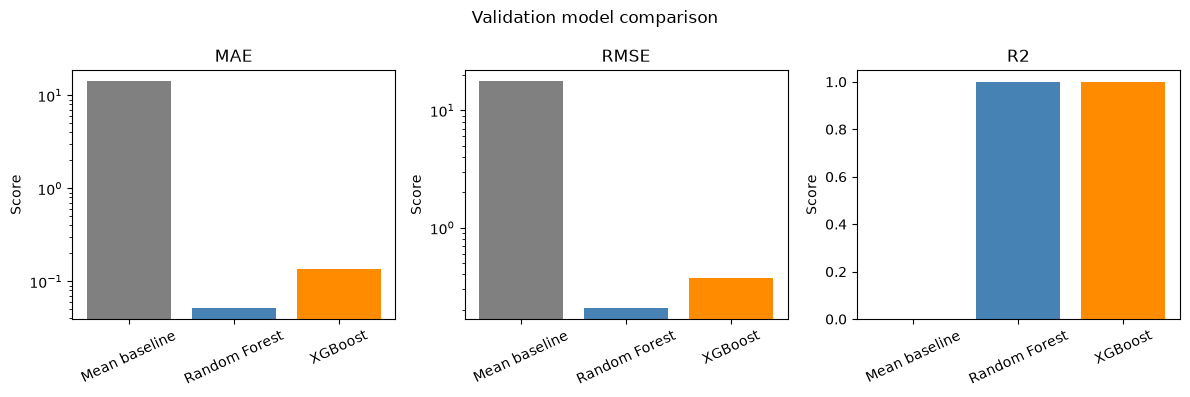

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    ax.bar(comparison['model'], comparison[metric], color=['gray', 'steelblue', 'darkorange'])
    ax.set_title(metric)
    ax.tick_params(axis='x', rotation=25)
    ax.set_ylabel('Score')
    if metric in ['MAE', 'RMSE']:
        ax.set_yscale('log')
fig.suptitle('Validation model comparison')
fig.tight_layout()
output_dir = data_dir / '04.ModelEvaluation'
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / 'model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
comparison.to_csv(output_dir / 'model_comparison.csv', index=False)

# Conclusion

In [6]:
best = comparison.loc[comparison['RMSE'].idxmin()]
print(f"Lowest validation RMSE: {best['model']} ({best['RMSE']:.4f}).")
print('These scores measure reconstruction of the CCME index from measurements taken at the same time, not future water-quality forecasting.')
print('The random split does not establish performance at unseen sites or future dates.')

Lowest validation RMSE: Random Forest (0.2081).
These scores measure reconstruction of the CCME index from measurements taken at the same time, not future water-quality forecasting.
The random split does not establish performance at unseen sites or future dates.
